# 05 — Intermittent demand: Seasonal Naive vs. Croston vs. TSB (Phase 3 · Step 1b)

Most products in a store do not sell every day. A packet of a slow-moving item may sell on one day, then not for a week, then
three units at once. Such an **intermittent** series is mostly zeros, and ordinary forecasting tools — and ordinary error
measures — behave strangely on it. This notebook is a real experiment on exactly that problem:

* **Data.** The 20 items selected in Phase 1 (5 per demand class: Smooth, Intermittent, Erratic, Lumpy) from store CA_1,
  department FOODS_3 — plus, as a robustness check, **all 823 items** of that department.
* **Models.** Three simple, standard baselines, with the settings fixed in `config.yaml` *before* any result existed:
  **Seasonal Naive** (repeat last week), **Croston** (average demand size ÷ average gap between demands) and **TSB**
  (probability of a demand day × average demand size).
* **Protocol.** The *same* five expanding walk-forward folds, the *same* 28-day horizon and the *same* metrics as every other
  experiment in the project (Phase 2 and notebooks 06 – 09). The Phase 2 item-level numbers are **reproduced** here and checked
  against the saved Phase 2 file; nothing from Phase 2 is overwritten.
* **Final holdout.** The last 28 days (2016-04-25 → 2016-05-22) are reserved for one final evaluation. They are **not read,
  fitted, tuned or reported anywhere in this notebook**; the loaders cut the data at the development window before anything else.

## 1. Objective

*On intermittent retail demand, how do Seasonal Naive, Croston and TSB compare when they are scored with several error measures,
per item and per demand class, on identical walk-forward folds — and does the picture change when the demand classes are
recomputed from each fold's own training data instead of from the full history?*

The notebook answers a narrower, measurable question than "which model is best": it reports **how each model behaves on these
folds**, how much the numbers move **between folds**, where the **error measures disagree with each other**, and why a
meaningless "forecast zero every day" reference can look good under some measures. It does not claim a universal winner.

## 2. Method — the ideas behind the experiment

### 2.1 What is intermittent demand?
A demand series is **intermittent** when many periods have zero demand. Two things matter and they are separate questions:

* **When does demand occur?** — the *interval* between demand days (or, equivalently, the *probability* that a given day has demand).
* **How much is demanded when it occurs?** — the demand *size*.

Average demand per day is the product of the two: `mean daily demand = probability of a demand day × mean size on a demand day`
(checked numerically in Section 3). Phase 1 used two numbers to sort items into four classes (the Syntetos–Boylan–Croston rule):
**ADI** = days ÷ demand days (large = rare demand) and **CV²** = squared coefficient of variation of the demand size
(large = erratic size). Thresholds: ADI = 1.32 and CV² = 0.49.

| | CV² < 0.49 (steady sizes) | CV² ≥ 0.49 (erratic sizes) |
|---|---|---|
| **ADI < 1.32** (sells almost daily) | Smooth | Erratic |
| **ADI ≥ 1.32** (sells rarely) | Intermittent | Lumpy |

### 2.2 Why ordinary forecasting and ordinary metrics struggle
* **Zero inflation.** A forecast that is a smooth positive number can never be exactly right on a zero day, and a forecast of
  zero is exactly wrong on every demand day.
* **MAE rewards the median.** The forecast that minimises the *mean absolute error* is the **median** of the demand distribution. For a
  series that is zero on most days the median is zero, so a forecast of 0 can have a *lower MAE* than an honest estimate of average demand —
  while being useless for stocking anything. RMSE (squared errors) rewards the **mean** instead. The two measures can rank models differently.
* **MAPE breaks on zeros.** It divides by the actual value, which is zero on most days. The zero-protected version used here drops those
  days and says how many were dropped — so it is computed on demand days only and ignores where most of the error lives.
* **WAPE and MASE.** *WAPE* = total absolute error ÷ total actual demand (undefined if there was no demand at all). *MASE* = MAE ÷ the MAE of a
  seasonal-naive forecast **on the training window** (undefined when that scale is zero). They make errors comparable across items of
  different volume, which MAE cannot.

### 2.3 The three models
* **Seasonal Naive** — the forecast for each day is the sales of the same weekday last week. No parameters. On an intermittent series it
  repeats last week's zeros *and* last week's spikes.
* **Croston (1972)** — look only at demand days. Smooth the demand *size* `z` and the *interval* `q` between demand days with the same weight
  `α`, and forecast `z ÷ q` for every future day. The forecast is a flat line.
* **TSB (Teunter–Syntetos–Babai, 2011)** — Croston's interval is only updated on demand days, so after a long run of zeros it stays stale.
  TSB instead smooths the **probability** `p` that a day has demand, updating it on **every** day (towards 1 on a demand day, towards 0
  on a zero day), and smooths the size `z` on demand days only. It forecasts `p × z`, also a flat line, but `p` decays during a dry spell.

All three are baselines with fixed settings (`α = 0.1`; TSB `β = 0.1`); none is tuned on a forecast window.

### 2.4 Experiment design
1. Cut every series at the development window; the final 28 days are never loaded.
2. Five expanding folds of 28 days (the project's walk-forward protocol): each model is fitted on the training prefix only and forecasts the next 28 days.
3. Score each (item, model, fold) with MAE, RMSE, zero-protected MAPE, WAPE, bias and MASE. Average over folds per item, then average items **equally** within a class
   (a *macro* average, so high-volume items do not dominate).
4. Add a **zero-forecast reference** ("always predict 0") to show what the measures reward. It is a yardstick, never a candidate model.
5. Re-run the three baselines on all 823 items and group them by **fold-local** demand class (Section 11).

> Item-level errors (units per item per day) are on a completely different scale from the aggregate series' errors (thousands of units per day).
> They are never ranked against each other here or anywhere else in the project.

## 3. Setup and reproducibility

Run from the project root with `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/05_intermittent_models.ipynb`
(about a minute), or open the notebook in VS Code / Jupyter and run all cells. Everything below is deterministic.

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Walk up from `start` until a directory containing config.yaml is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find config.yaml in any parent directory of '{start}'. Run this notebook from within the project."
    )


PROJECT_ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.evaluation import intermittent_experiment as ix
from src.evaluation.forecast_artifacts import (
    audit_forecast_table,
    expected_fold_windows,
    load_selected_item_series,
    read_forecast_table,
    write_forecast_table,
)
from src.evaluation.item_level import plot_example_item_forecasts
from src.models.croston import CrostonForecaster
from src.models.tsb import TSBForecaster
from src.utils.config import load_config
from src.utils.paths import resolve_path
from src.utils.provenance import build_run_metadata, library_versions, write_json

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("src.evaluation.backtesting").setLevel(logging.CRITICAL)  # a failed fold is reported in the tables, not as log noise
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

config = load_config()
p2, p3 = config["phase2"], config["phase3"]
HORIZON, N_FOLDS = int(config["backtest"]["horizon"]), int(config["backtest"]["n_folds"])
forecasts_dir = PROJECT_ROOT / p3["forecasts_dir"]
metrics_dir = PROJECT_ROOT / p3["metrics_dir"]
reports_dir = PROJECT_ROOT / config["reports"]["phase3_dir"]
for directory in (forecasts_dir, metrics_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    fig.savefig(reports_dir / filename, dpi=150, bbox_inches="tight")


versions = library_versions(["pandas", "numpy", "matplotlib"])
print("Python", sys.version.split()[0], "| pandas", versions["pandas"], "| numpy", versions["numpy"])
print("Backtest settings:", config["backtest"])
print("Smoothing settings:", {k: v for k, v in config["models"].items() if k in ("croston_alpha", "tsb_alpha", "tsb_beta")})

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3
Backtest settings: {'holdout_days': 28, 'horizon': 28, 'n_folds': 5, 'season_length': 7}
Smoothing settings: {'croston_alpha': 0.1, 'tsb_alpha': 0.1, 'tsb_beta': 0.1}


In [2]:
# The ONLY way this notebook gets item series: development window only, holdout already cut off.
series_by_item = load_selected_item_series(config)
labels_path = resolve_path(Path(config["data"]["processed_dir"]) / config["output"]["selected_items_daily_sales_filename"])
labels = pd.read_parquet(labels_path, columns=["item_id", "demand_class"]).drop_duplicates().set_index("item_id")["demand_class"]
classes = {item_id: str(labels.loc[item_id]) for item_id in series_by_item}

index = next(iter(series_by_item.values())).index
assert all(s.index.equals(index) for s in series_by_item.values()), "all items must share one calendar"
print(f"{len(series_by_item)} selected items, {len(index)} development days each, {index[0].date()} -> {index[-1].date()}")
print(f"Reserved final holdout: {(index[-1] + pd.Timedelta(days=1)).date()} -> {(index[-1] + pd.Timedelta(days=28)).date()} (dates only; its sales are not loaded here)")
print("Phase 1 classes of the selected items:", pd.Series(classes).value_counts().reindex(ix.CLASS_ORDER).to_dict())

windows = expected_fold_windows(index, HORIZON, N_FOLDS)
print("\nThe five expanding development folds (identical for every model and item):")
print(windows.to_string(index=False))

20 selected items, 1913 development days each, 2011-01-29 -> 2016-04-24
Reserved final holdout: 2016-04-25 -> 2016-05-22 (dates only; its sales are not loaded here)
Phase 1 classes of the selected items: {'Smooth': 5, 'Intermittent': 5, 'Erratic': 5, 'Lumpy': 5}

The five expanding development folds (identical for every model and item):
 fold  n_train origin_date forecast_start forecast_end
    1     1773  2015-12-06     2015-12-07   2016-01-03
    2     1801  2016-01-03     2016-01-04   2016-01-31
    3     1829  2016-01-31     2016-02-01   2016-02-28
    4     1857  2016-02-28     2016-02-29   2016-03-27
    5     1885  2016-03-27     2016-03-28   2016-04-24


## 4. Demand patterns of the selected items

The table gives, for each item over the development window: the share of days with zero sales, the probability of a demand day, the
average demand size on demand days, the average gap between demand days, ADI, CV², and the zero-run statistics (a *zero run* is a stretch of
consecutive days with no sales).

In [3]:
patterns = ix.demand_pattern_table(series_by_item, classes)
show = patterns[["item_id", "demand_class", "zero_share", "occurrence_probability", "mean_size", "mean_interval", "ADI", "CV2",
                 "mean_daily_demand", "leading_zero_days", "longest_zero_run"]].copy()
show["zero_share"] = (show["zero_share"] * 100).round(1)
show = show.rename(columns={"zero_share": "zero_days_%", "occurrence_probability": "P(demand day)", "mean_size": "size|demand",
                            "mean_interval": "gap_days", "mean_daily_demand": "mean/day", "leading_zero_days": "days_before_first_sale"})
display(show.round(3).set_index("item_id"))

print("\nBy class (median over the 5 items of each class):")
by_class = patterns.groupby("demand_class").median(numeric_only=True).reindex(ix.CLASS_ORDER)
display(by_class[["zero_share", "occurrence_probability", "mean_size", "mean_interval", "ADI", "CV2", "mean_daily_demand", "longest_zero_run"]].round(3))

identity_gap = (patterns["mean_daily_demand"] - patterns["occurrence_probability"] * patterns["mean_size"]).abs().max()
print(f"\nCheck: mean daily demand = P(demand day) x mean size, largest difference over the 20 items: {identity_gap:.2e}")
leading = patterns[patterns["leading_zero_days"] >= 28]
print(f"{len(leading)} of 20 items have at least 28 zero days BEFORE their first sale (longest: {int(patterns['leading_zero_days'].max())} days). "
      "Those days are most likely a period when the item was not yet on sale. They stay in the data (nothing is deleted or imputed) "
      "and they inflate the zero share, ADI and the longest zero run of the full history; the classes used for model selection in Section 11 are computed on each fold's training prefix.")

,demand_class,zero_days_%,P(demand day),size|demand,gap_days,ADI,CV2,mean/day,days_before_first_sale,longest_zero_run
item_id,,,,,,,,,,
FOODS_3_067,Smooth,17.9,0.821,2.868,1.218,1.218,0.343,2.355,2,16
FOODS_3_230,Smooth,5.2,0.948,4.156,1.055,1.055,0.465,3.941,0,3
FOODS_3_263,Smooth,19.3,0.807,8.678,1.240,1.240,0.289,6.999,0,350
FOODS_3_330,Smooth,16.2,0.838,4.417,1.193,1.193,0.432,3.704,0,78
FOODS_3_348,Smooth,21.0,0.790,7.517,1.265,1.265,0.446,5.941,0,172
FOODS_3_042,Intermittent,32.1,0.679,3.926,1.473,1.473,0.478,2.666,104,304
FOODS_3_206,Intermittent,73.8,0.262,2.992,3.811,3.811,0.449,0.785,934,934
FOODS_3_264,Intermittent,95.4,0.046,1.636,21.693,21.739,0.311,0.075,1685,1685
FOODS_3_341,Intermittent,74.2,0.258,1.476,3.870,3.872,0.325,0.381,0,474



By class (median over the 5 items of each class):


,zero_share,occurrence_probability,mean_size,mean_interval,ADI,CV2,mean_daily_demand,longest_zero_run
demand_class,,,,,,,,
Smooth,0.179,0.821,4.417,1.218,1.218,0.432,3.941,78.0
Intermittent,0.742,0.258,2.343,3.870,3.872,0.428,0.386,934.0
Erratic,0.185,0.815,9.428,1.212,1.227,0.714,7.619,83.0
Lumpy,0.590,0.410,2.798,2.431,2.437,0.535,1.741,417.0



Check: mean daily demand = P(demand day) x mean size, largest difference over the 20 items: 1.78e-15
7 of 20 items have at least 28 zero days BEFORE their first sale (longest: 1685 days). Those days are most likely a period when the item was not yet on sale. They stay in the data (nothing is deleted or imputed) and they inflate the zero share, ADI and the longest zero run of the full history; the classes used for model selection in Section 11 are computed on each fold's training prefix.


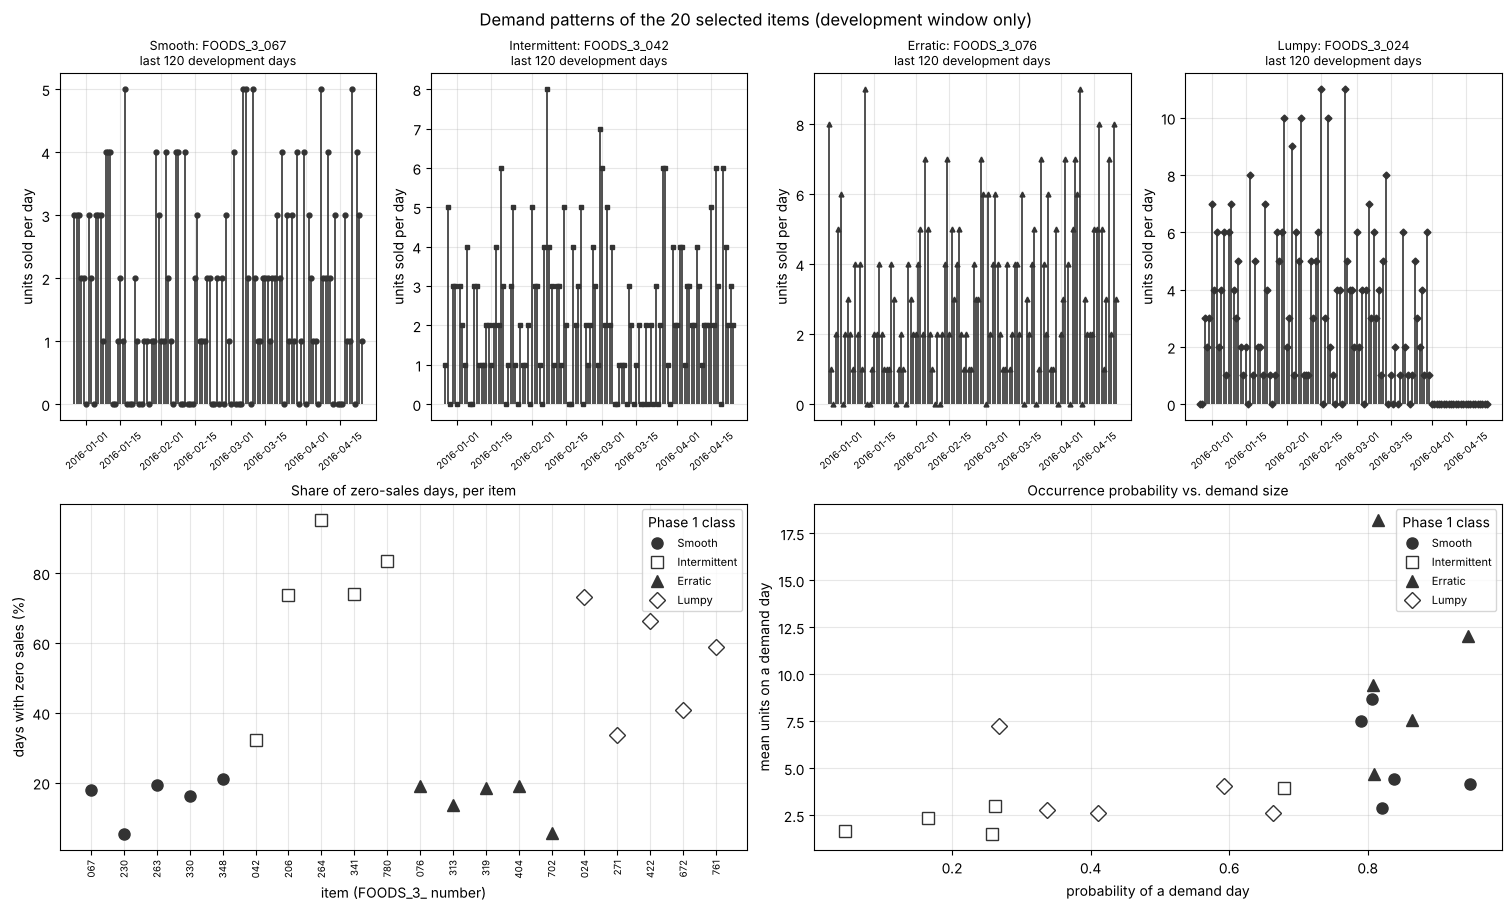

In [4]:
fig = ix.plot_demand_patterns(series_by_item, patterns)
save_figure(fig, p3["intermittent_patterns_plot_filename"])
plt.show()

### 4.1 How long do the dry spells last?

A forecaster that predicts a small positive number every day is, in effect, spreading demand evenly over the dry spells. How long those spells are
tells us how far that picture is from reality.

,n_runs,median,mean,longest,share_7_plus
demand_class,,,,,
Smooth,604,1.0,2.518,350,0.013
Intermittent,655,2.0,10.484,1685,0.079
Erratic,401,1.0,3.621,91,0.072
Lumpy,871,1.0,5.994,1129,0.062


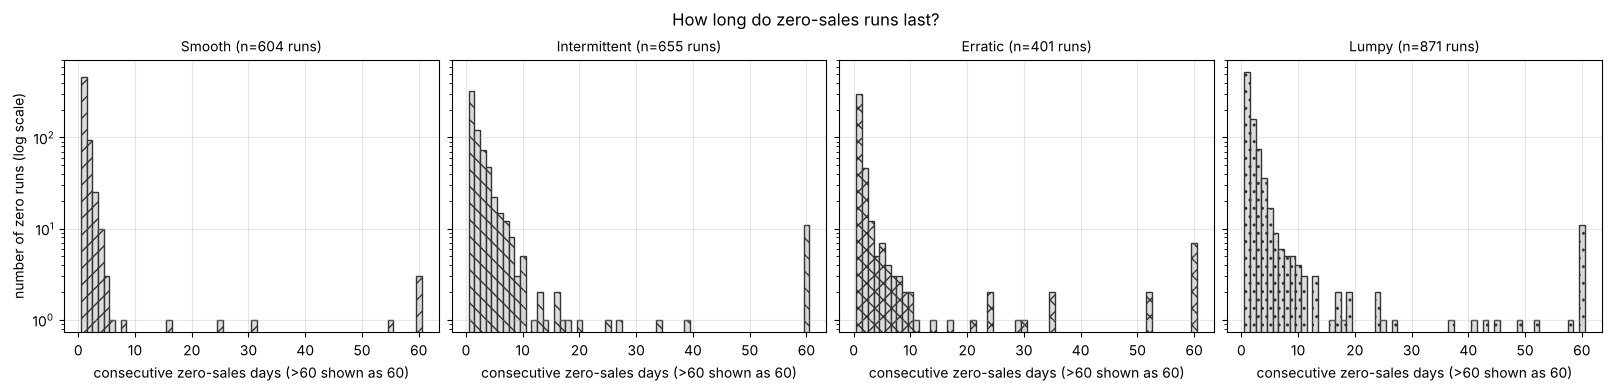

In [5]:
runs = ix.zero_run_table(series_by_item, classes)
run_stats = (
    runs.groupby("demand_class")["run_length"]
    .agg(n_runs="count", median="median", mean="mean", longest="max",
         share_7_plus=lambda s: float((s >= 7).mean()))
    .reindex(ix.CLASS_ORDER)
)
display(run_stats.round(3))
fig = ix.plot_zero_runs(runs)
save_figure(fig, p3["intermittent_zero_runs_plot_filename"])
plt.show()

## 5. The models, step by step on a tiny series

Before trusting the library classes, here are Croston and TSB written out by hand on a 14-day toy series. The hand-written recursion is then
**checked against** the project's `CrostonForecaster` and `TSBForecaster`: if they disagree the notebook stops.

In [6]:
toy = [0, 0, 3, 0, 0, 0, 2, 0, 4, 0, 0, 0, 0, 5]
ALPHA, BETA = config["models"]["croston_alpha"], config["models"]["tsb_beta"]
TSB_ALPHA = config["models"]["tsb_alpha"]


def croston_trace(values, alpha):
    z = q = None
    since = 0
    rows = []
    for day, y in enumerate(values, start=1):
        since += 1
        if y > 0:
            if z is None:
                z, q = float(y), float(since)           # first demand: seed with its size and its position
            else:
                z = alpha * y + (1 - alpha) * z
                q = alpha * since + (1 - alpha) * q
            since = 0
        rows.append({"day": day, "sales": y, "size z": z, "interval q": q, "forecast z/q": None if z is None else z / q})
    return pd.DataFrame(rows)


def tsb_trace(values, alpha, beta):
    p, z = 0.0, 0.0
    rows = []
    for day, y in enumerate(values, start=1):
        if y > 0:
            z = beta * y + (1 - beta) * z               # size updated on demand days only
        p = alpha * (1.0 if y > 0 else 0.0) + (1 - alpha) * p   # probability updated EVERY day
        rows.append({"day": day, "sales": y, "probability p": p, "size z": z, "forecast p*z": p * z})
    return pd.DataFrame(rows)


croston_toy, tsb_toy = croston_trace(toy, ALPHA), tsb_trace(toy, TSB_ALPHA, BETA)
display(croston_toy.round(3).set_index("day"))
display(tsb_toy.round(3).set_index("day"))

croston_lib = CrostonForecaster(alpha=ALPHA).fit(pd.Series(toy, dtype=float)).fit_diagnostics()
tsb_lib = TSBForecaster(alpha=TSB_ALPHA, beta=BETA).fit(pd.Series(toy, dtype=float)).fit_diagnostics()
assert abs(croston_toy["forecast z/q"].iloc[-1] - croston_lib["forecast_value"]) < 1e-12
assert abs(tsb_toy["forecast p*z"].iloc[-1] - tsb_lib["forecast_value"]) < 1e-12
print(f"Hand-written recursion equals the library classes: Croston forecast {croston_lib['forecast_value']:.4f}, TSB forecast {tsb_lib['forecast_value']:.4f} units/day.")
print("Seasonal Naive on this series would instead repeat days 8-14 as next week's forecast:", toy[-7:])

,sales,size z,interval q,forecast z/q
day,,,,
1,0,NaN,NaN,NaN
2,0,NaN,NaN,NaN
3,3,3.000,3.000,1.000
4,0,3.000,3.000,1.000
5,0,3.000,3.000,1.000
6,0,3.000,3.000,1.000
7,2,2.900,3.100,0.935
8,0,2.900,3.100,0.935
9,4,3.010,2.990,1.007


,sales,probability p,size z,forecast p*z
day,,,,
1,0,0.000,0.000,0.000
2,0,0.000,0.000,0.000
3,3,0.100,0.300,0.030
4,0,0.090,0.300,0.027
5,0,0.081,0.300,0.024
6,0,0.073,0.300,0.022
7,2,0.166,0.470,0.078
8,0,0.149,0.470,0.070
9,4,0.234,0.823,0.193


Hand-written recursion equals the library classes: Croston forecast 1.0056, TSB forecast 0.2956 units/day.
Seasonal Naive on this series would instead repeat days 8-14 as next week's forecast: [0, 4, 0, 0, 0, 0, 5]


## 6. The experiment: three models × 20 items × 5 folds

`run_item_baselines` calls the project's existing walk-forward backtest (unmodified) once per (item, model). A fold that fails keeps its rows,
with the error text, instead of disappearing. Then the fresh run is **compared with the saved Phase 2 item-level fold metrics**.

In [7]:
factories = ix.baseline_factories(config)
print("Models:", list(factories))

started = time.perf_counter()
long_table, fold_summary = ix.run_item_baselines(series_by_item, classes, factories, HORIZON, N_FOLDS)
elapsed = time.perf_counter() - started
n_failed = int((~fold_summary["success"]).sum())
print(f"{len(fold_summary)} (item, model, fold) fits in {elapsed:.1f} s; failed folds: {n_failed}; forecast rows: {len(long_table)}")

phase2_path = resolve_path(Path(p2["metrics_dir"]) / p2["item_level_fold_summary_filename"])
if phase2_path.exists():
    reproduction = ix.reproduction_check(fold_summary, pd.read_csv(phase2_path))
    print("\nReproduction of the saved Phase 2 item-level fold metrics:")
    for key, value in reproduction.items():
        print(f"  {key}: {value}")
    assert reproduction["reproduced"], "The fresh run does not reproduce the saved Phase 2 results; investigate before continuing."
    print("-> The fresh run reproduces every saved Phase 2 MAE, RMSE and MAPE (to the stated tolerance).")
else:
    reproduction = None
    print(f"\nPhase 2 file '{phase2_path.name}' not found, so reproduction cannot be checked here. Create it with notebook 04 / the Phase 2 pipeline.")

Models: ['SeasonalNaive', 'Croston(alpha=0.1)', 'TSB(alpha=0.1,beta=0.1)']


300 (item, model, fold) fits in 0.4 s; failed folds: 0; forecast rows: 8400

Reproduction of the saved Phase 2 item-level fold metrics:
  reproduced: True
  n_compared: 300
  n_only_in_new_run: 0
  n_only_in_saved_file: 0
  max_abs_diff_MAE: 3.552713678800501e-15
  max_abs_diff_RMSE: 8.881784197001252e-16
  max_abs_diff_MAPE: 1.4210854715202004e-14
  tolerance: 1e-09
-> The fresh run reproduces every saved Phase 2 MAE, RMSE and MAPE (to the stated tolerance).


### 6.1 Scoring and saving

Metrics are recomputed from the saved forecasts by the shared `metrics_by_group` function. The MASE scale of each (item, fold) is the mean absolute
seasonal (lag-7) difference of that item's **training** window; where it is zero (an item that never changes week to week) MASE is undefined and left blank.

In [8]:
zero_long = ix.zero_forecast_long_table(long_table)
scales = ix.item_mase_scales(series_by_item, HORIZON, N_FOLDS)
fold_metrics = ix.score_long_table(long_table, scales)
zero_fold_metrics = ix.score_long_table(zero_long, scales)

item_tab = ix.item_summary(fold_metrics)
class_tab = ix.class_summary(item_tab)
zero_item_tab = ix.item_summary(zero_fold_metrics)
zero_class_tab = ix.class_summary(zero_item_tab)

write_forecast_table(long_table, forecasts_dir / p3["intermittent_long_filename"])
fold_metrics.to_csv(metrics_dir / p3["intermittent_fold_summary_filename"], index=False, lineterminator="\n")
item_tab.to_csv(metrics_dir / p3["intermittent_per_item_summary_filename"], index=False, lineterminator="\n")
class_tab.to_csv(metrics_dir / p3["intermittent_category_summary_filename"], index=False, lineterminator="\n")
zero_item_tab.to_csv(metrics_dir / p3["intermittent_zero_reference_filename"], index=False, lineterminator="\n")

print(f"Saved {p3['intermittent_long_filename']} ({len(long_table)} rows), plus fold, per-item, per-class and zero-reference metric tables.")
print(f"MASE undefined (zero training scale) in {int(scales['mase_scale'].isna().sum())} of {len(scales)} (item, fold) cells.")

saved = read_forecast_table(forecasts_dir / p3["intermittent_long_filename"], kind="item")
audit = audit_forecast_table(saved, kind="item", item_series=series_by_item, dev_dates=index, horizon=HORIZON, n_folds=N_FOLDS)
for check in audit:
    print(f"{'PASS' if check.passed else 'FAIL'} - {check.name} - {check.detail}")
assert all(check.passed for check in audit), "The saved forecast table failed an integrity check."

Saved intermittent_item_level_backtest_long.csv (8400 rows), plus fold, per-item, per-class and zero-reference metric tables.
MASE undefined (zero training scale) in 0 of 100 (item, fold) cells.


PASS - no_dates_after_development_end - ok
PASS - no_duplicate_rows - 0 duplicated row(s)
PASS - folds_and_windows_match_protocol - ok
PASS - actuals_equal_development_series - ok
PASS - predictions_finite_on_successful_rows - 0 non-finite prediction(s)
PASS - predictions_non_negative - 0 negative prediction(s)


## 7. Results — per item

MAE, RMSE, WAPE and MASE are averaged over each item's five folds (lower is better for every one of them; `bias` > 0 would mean over-forecasting and is in the saved files). `SN` = Seasonal Naive.
Blank MASE / WAPE means the measure was undefined for that item.

In [9]:
short = {m: m.split("(")[0] for m in item_tab["model"].unique()}
wide_items = item_tab.assign(model=item_tab["model"].map(short)).pivot_table(
    index=["demand_class", "item_id"], columns="model",
    values=["MAE_mean", "RMSE_mean", "WAPE_mean", "MASE_mean"], observed=True,
)
wide_items.columns = [f"{metric.replace('_mean', '')} {model}" for metric, model in wide_items.columns]
order = {c: i for i, c in enumerate(ix.CLASS_ORDER)}
wide_items = wide_items.sort_index(key=lambda idx: idx.map(order) if idx.name == "demand_class" else idx)
metric_order = [f"{m} {model}" for m in ("MAE", "RMSE", "WAPE", "MASE") for model in ("SeasonalNaive", "Croston", "TSB")]
display(wide_items[metric_order].round(3))

MAE SeasonalNaive  MAE Croston  MAE TSB  RMSE SeasonalNaive  RMSE Croston  RMSE TSB  WAPE SeasonalNaive  WAPE Croston  WAPE TSB  MASE SeasonalNaive  MASE Croston  MASE TSB
demand_class item_id                                                                                                                                                                                 
Smooth       FOODS_3_067              1.650        1.306    1.312               2.061         1.546     1.551               0.965         0.766     0.770               0.894         0.707     0.711
             FOODS_3_230              3.057        2.264    2.265               4.336         3.276     3.275               1.029         0.753     0.755               1.155         0.855     0.856
             FOODS_3_263              2.714        3.292    2.257               3.741         4.115     3.190               0.742         1.297     0.629               0.823         0.996     0.685
             FOODS_3_330              2.400        2.199    2.191               3.101         2.755     2.760               0.742         0.679     0.676               0.896         0.821     0.818
             FOODS_3_348              4.879        3.457    3.462               6.123         4.395     4.400               0.653         0.460     0.461               1.107         0.784     0.786
Intermittent FOODS_3_042              1.886        1.498    1.501               2.419         1.858     1.865               0.849         0.676     0.677               1.114         0.885     0.887
             FOODS_3_206              0.836        1.226    0.818               1.236         1.426     1.106               3.702         4.033     4.378               1.098         1.609     1.075
             FOODS_3_264              0.743        0.688    0.684               1.170         1.030     0.884               1.093         1.006     1.047              11.564        10.550    10.690
             FOODS_3_341              0.871        0.759    0.761               1.320         0.966     0.968               1.426         1.244     1.250               1.645         1.432     1.436
             FOODS_3_780              1.179        0.989    0.963               1.599         1.312     1.291               1.241         1.055     1.011               3.125         2.623     2.559
Erratic      FOODS_3_076              2.250        1.904    1.903               2.883         2.345     2.341               0.750         0.628     0.627               0.790         0.669     0.668
             FOODS_3_313              2.843        2.311    2.314               3.565         2.829     2.830               0.521         0.428     0.428               0.632         0.514     0.515
             FOODS_3_319              5.871        6.226    5.107               7.440         7.275     6.585               2.227         2.339     1.891               0.701         0.740     0.609
             FOODS_3_404              4.657        7.988    4.005               5.919         8.736     5.087               1.951         4.060     1.928               0.847         1.445     0.729
             FOODS_3_702              4.571        3.520    3.609               5.778         4.343     4.473               0.561         0.441     0.452               0.737         0.568     0.582
Lumpy        FOODS_3_024              2.279        2.989    2.143               3.124         3.449     2.714               1.688         2.648     1.808               1.626         2.143     1.530
             FOODS_3_271              1.500        1.832    1.400               2.076         2.128     1.693               1.227         1.075     1.082               1.038         1.267     0.968
             FOODS_3_422              1.300        1.245    1.187               1.726         1.536     1.437               0.978         0.908     0.912               1.305         1.249     1.190
             FOODS_3_672              0.586        1.251    0.540 

## 8. Results — per demand class (macro average over items)

Every item counts equally. `MAPE` is on demand days only and `n` says for how many items it was defined — read it as a descriptive number, not as a ranking
criterion, for the reason given in Section 2.2. The last rows of each class are the **zero-forecast reference**.

In [10]:
def class_table(summary):
    cols = ["demand_class", "model", "n_items", "MAE_macro_mean", "RMSE_macro_mean", "MAPE_macro_mean", "MAPE_n_items_valid",
            "WAPE_macro_mean", "MASE_macro_mean", "MASE_n_items_valid", "bias_macro_mean"]
    out = summary[cols].rename(columns={
        "MAE_macro_mean": "MAE", "RMSE_macro_mean": "RMSE", "MAPE_macro_mean": "MAPE_%", "MAPE_n_items_valid": "MAPE_n",
        "WAPE_macro_mean": "WAPE", "MASE_macro_mean": "MASE", "MASE_n_items_valid": "MASE_n", "bias_macro_mean": "bias"})
    return out


combined_classes = pd.concat([class_tab, zero_class_tab], ignore_index=True)
combined_classes["_r"] = combined_classes["demand_class"].map(order)
combined_classes = combined_classes.sort_values(["_r", "model"], kind="stable").drop(columns="_r")
display(class_table(combined_classes).round(3).set_index(["demand_class", "model"]))

n_items    MAE   RMSE   MAPE_%  MAPE_n   WAPE   MASE  MASE_n   bias
demand_class model                                                                                       
Smooth       Croston(alpha=0.1)             5  2.504  3.217   64.836       5  0.791  0.833       5 -0.098
             SeasonalNaive                  5  2.940  3.872   87.268       5  0.826  0.975       5  0.066
             TSB(alpha=0.1,beta=0.1)        5  2.298  3.035   67.613       5  0.658  0.771       5 -0.112
             ZeroForecast(reference)        5  4.077  5.011  100.000       5  1.000  1.305       5 -4.077
Intermittent Croston(alpha=0.1)             5  1.032  1.318   58.047       5  1.603  3.420       5 -0.015
             SeasonalNaive                  5  1.103  1.549   77.801       5  1.662  3.709       5 -0.089
             TSB(alpha=0.1,beta=0.1)        5  0.946  1.223   51.700       5  1.673  3.330       5 -0.049
             ZeroForecast(reference)        5  1.043  1.575  100.000       5  1.000  3.311       5 -1.043
Erratic      Croston(alpha=0.1)             5  4.390  5.106   71.400       5  1.579  0.787       5  1.113
             SeasonalNaive                  5  4.039  5.117   78.123       5  1.202  0.742       5  0.736
             TSB(alpha=0.1,beta=0.1)        5  3.388  4.263   67.833       5  1.065  0.621       5  0.408
             ZeroForecast(reference)        5  5.539  6.738  100.000       5  1.000  1.048       5 -5.539
Lumpy        Croston(alpha=0.1)             5  1.594  1.862   65.245       5  1.393  1.171       5  0.295
             SeasonalNaive                  5  1.289  1.795   90.879       5  1.326  1.002       5  0.014
             TSB(alpha=0.1,beta=0.1)        5  1.185  1.480   69.958       5  1.217  0.918       5  0.021
             ZeroForecast(reference)        5  1.260  1.814  100.000       5  1.000  0.978       5 -1.260

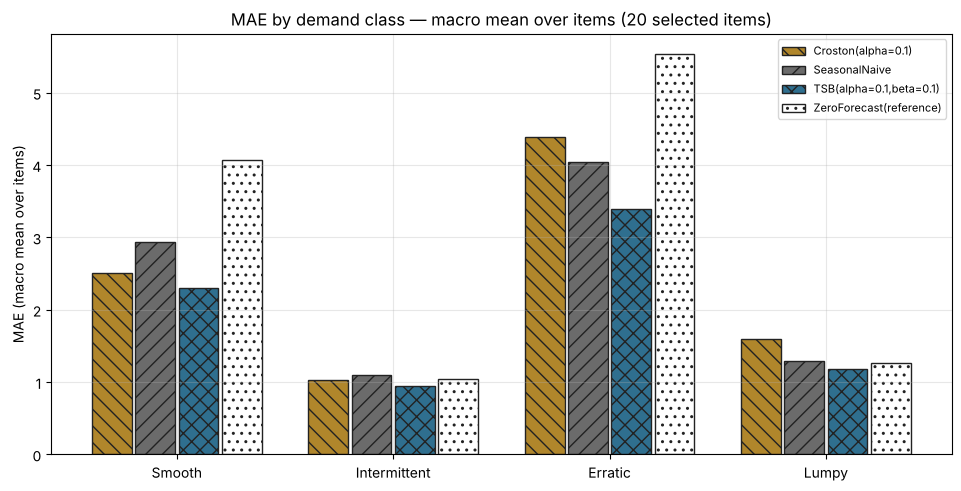

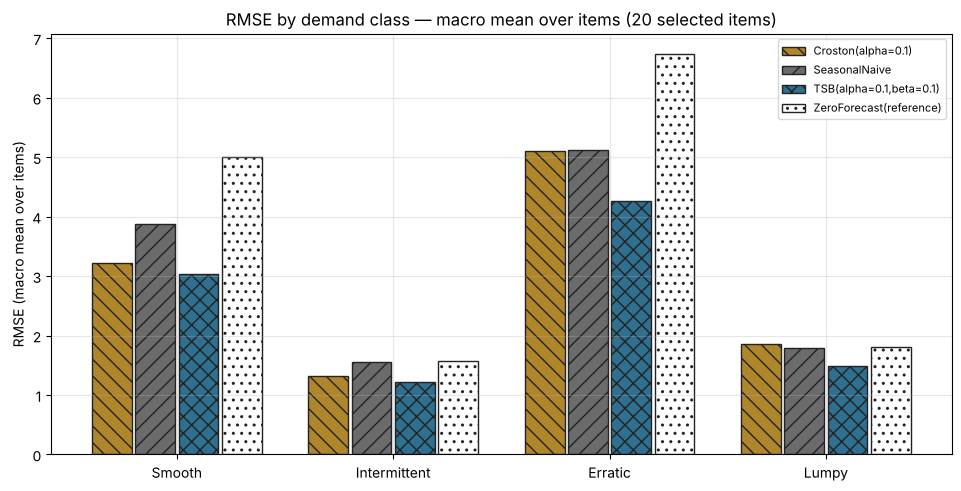

In [11]:
fig = ix.plot_class_metric(combined_classes, "MAE", title="MAE by demand class — macro mean over items (20 selected items)")
save_figure(fig, p3["intermittent_category_mae_plot_filename"])
plt.show()
fig = ix.plot_class_metric(combined_classes, "RMSE", title="RMSE by demand class — macro mean over items (20 selected items)")
save_figure(fig, p3["intermittent_category_rmse_plot_filename"])
plt.show()

### 8.1 Variation between folds

One average hides how much the numbers move from one forecast window to the next. The table shows each class's macro-mean MAE in each fold; the last two columns
are the mean and the standard deviation across the five folds.

In [12]:
fold_class = (
    fold_metrics[fold_metrics["success"].astype(bool)]
    .groupby(["demand_class", "model", "fold"])["MAE"].mean().unstack("fold")
)
fold_class.columns = [f"fold {c}" for c in fold_class.columns]
fold_class["mean"] = fold_class.mean(axis=1)
fold_class["std (folds)"] = fold_class[[c for c in fold_class.columns if c.startswith("fold")]].std(axis=1, ddof=1)
fold_class = fold_class.reset_index()
fold_class["_r"] = fold_class["demand_class"].map(order)
fold_class = fold_class.sort_values(["_r", "model"], kind="stable").drop(columns="_r").set_index(["demand_class", "model"])
display(fold_class.round(3))
print("Folds are consecutive 28-day windows; a class-mean MAE that moves by this much between neighbouring windows is noise that any conclusion has to survive.")

fold 1  fold 2  fold 3  fold 4  fold 5   mean  std (folds)
demand_class model                                                                              
Smooth       Croston(alpha=0.1)        2.866   2.545   2.312   2.338   2.458  2.504        0.223
             SeasonalNaive             3.029   3.279   2.700   2.893   2.800  2.940        0.225
             TSB(alpha=0.1,beta=0.1)   2.157   2.337   2.203   2.329   2.462  2.298        0.121
Intermittent Croston(alpha=0.1)        0.921   0.890   1.060   1.136   1.153  1.032        0.121
             SeasonalNaive             1.079   1.114   0.929   1.021   1.371  1.103        0.166
             TSB(alpha=0.1,beta=0.1)   0.932   0.928   0.822   0.889   1.156  0.946        0.126
Erratic      Croston(alpha=0.1)        7.231   3.810   2.794   2.932   5.182  4.390        1.851
             SeasonalNaive             3.550   3.957   3.000   3.643   6.043  4.039        1.172
             TSB(alpha=0.1,beta=0.1)   2.926   3.185   2.689   2.953   5.184  3.388        1.019
Lumpy        Croston(alpha=0.1)        1.591   1.523   1.617   1.539   1.700  1.594        0.071
             SeasonalNaive             0.643   1.307   1.579   1.714   1.200  1.289        0.415
             TSB(alpha=0.1,beta=0.1)   0.596   1.208   1.307   1.519   1.297  1.185        0.349

Folds are consecutive 28-day windows; a class-mean MAE that moves by this much between neighbouring windows is noise that any conclusion has to survive.


## 9. The zero-forecast reference: what do the measures reward?

For every class, how does "always forecast 0" compare with the three models? A model that cannot beat this on a measure has not shown that it
adds information on that measure — and a model that *does* beat it on MAE can still be useless for stocking, because it never forecasts any demand.

In [13]:
real = fold_metrics.assign(model=fold_metrics["model"].map(short))
item_real = item_tab.assign(model=item_tab["model"].map(short)).set_index(["item_id", "model"])
item_zero = zero_item_tab.set_index("item_id")

rows = []
for model in ("SeasonalNaive", "Croston", "TSB"):
    mae = item_real.xs(model, level="model")["MAE_mean"]
    rmse = item_real.xs(model, level="model")["RMSE_mean"]
    zero_mae, zero_rmse = item_zero["MAE_mean"].reindex(mae.index), item_zero["RMSE_mean"].reindex(rmse.index)
    rows.append({
        "model": model,
        "items where zero has LOWER MAE": int((zero_mae < mae).sum()),
        "items where zero has LOWER RMSE": int((zero_rmse < rmse).sum()),
        "of items": int(len(mae)),
    })
display(pd.DataFrame(rows).set_index("model"))

zero_bias = zero_class_tab.set_index("demand_class")["bias_macro_mean"].reindex(ix.CLASS_ORDER)
print("\nThe zero forecast's mean error (forecast - actual) per class is exactly minus the mean daily demand, i.e. it under-forecasts every demand day:")
print(zero_bias.round(3).to_string())

,items where zero has LOWER MAE,items where zero has LOWER RMSE,of items
model,,,
SeasonalNaive,7,5,20
Croston,9,5,20
TSB,4,1,20



The zero forecast's mean error (forecast - actual) per class is exactly minus the mean daily demand, i.e. it under-forecasts every demand day:
demand_class
Smooth         -4.077
Intermittent   -1.043
Erratic        -5.539
Lumpy          -1.260


## 10. What did Croston and TSB actually learn?

At each fold origin, the fitted internal states are compared with the **empirical** quantities of the training window (probability of a demand day, mean size on
demand days, ADI), and the resulting flat forecast level is compared with the demand that actually occurred in the following 28 days
(`window_mean_actual` — an evaluation reference, never an input of any fit).

In [14]:
states = ix.smoothing_state_table(
    series_by_item, classes, HORIZON, N_FOLDS,
    croston_alpha=config["models"]["croston_alpha"], tsb_alpha=config["models"]["tsb_alpha"], tsb_beta=config["models"]["tsb_beta"],
)
states.to_csv(metrics_dir / p3["intermittent_state_diagnostics_filename"], index=False, lineterminator="\n")
print(f"{len(states)} (item, fold) state rows saved to {p3['intermittent_state_diagnostics_filename']}; Croston undefined in {int((states['croston_status'] != 'ok').sum())} of them (no demand in the training prefix).")

by_state = states.groupby("demand_class").mean(numeric_only=True).reindex(ix.CLASS_ORDER)
display(by_state[["train_probability", "tsb_probability", "train_interval", "croston_interval", "train_mean_size", "croston_size", "tsb_size"]].round(3))
print("Forecast level minus the demand actually realised in the next 28 days (mean over items and folds; > 0 = the flat forecast sat above realised demand):")
display(by_state[["window_mean_actual", "croston_forecast", "tsb_forecast", "croston_level_error", "tsb_level_error"]].round(3))

100 (item, fold) state rows saved to intermittent_state_diagnostics.csv; Croston undefined in 0 of them (no demand in the training prefix).


,train_probability,tsb_probability,train_interval,croston_interval,train_mean_size,croston_size,tsb_size
demand_class,,,,,,,
Smooth,0.839,0.821,1.197,2.051,5.560,4.726,4.726
Intermittent,0.273,0.498,12.611,12.611,2.533,1.947,1.935
Erratic,0.850,0.828,1.181,1.480,10.525,7.906,7.906
Lumpy,0.453,0.445,2.529,2.645,3.970,2.698,2.698


Forecast level minus the demand actually realised in the next 28 days (mean over items and folds; > 0 = the flat forecast sat above realised demand):


,window_mean_actual,croston_forecast,tsb_forecast,croston_level_error,tsb_level_error
demand_class,,,,,
Smooth,4.077,3.979,3.966,-0.098,-0.112
Intermittent,1.043,1.028,0.993,-0.015,-0.049
Erratic,5.539,6.652,5.947,1.113,0.408
Lumpy,1.260,1.555,1.281,0.295,0.021


Reading the first table: TSB starts its probability and size states at 0 and climbs towards the data, so it can lag when a series is short or when demand has risen; Croston's
interval state is only ever updated on demand days. Neither state is the empirical average — they are exponentially weighted, so they follow *recent* history. The second table shows
whether the resulting flat line sat above or below what really happened.

### 10.1 Example forecasts

Fold 5 (the most recent development window) for the first item of each class. Forecasts are flat lines for Croston and TSB; Seasonal Naive replays last week.

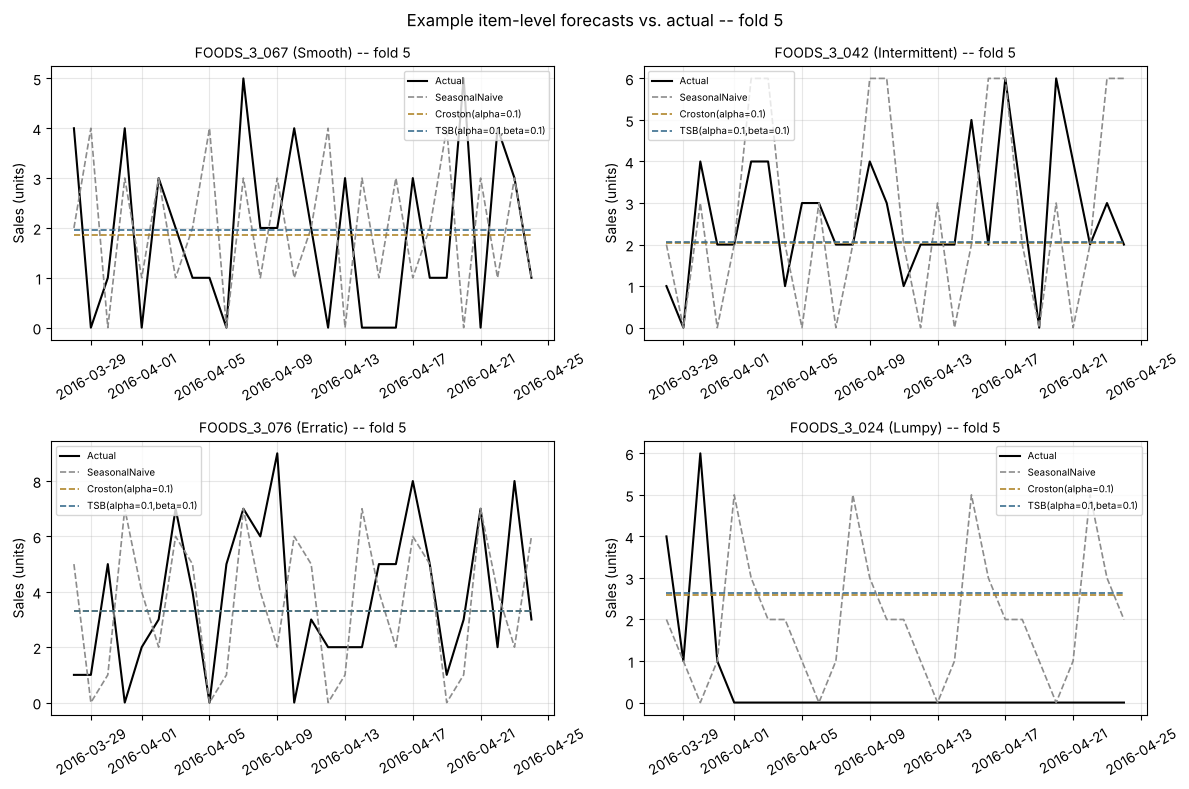

In [15]:
example_items = [patterns.loc[patterns["demand_class"] == c, "item_id"].iloc[0] for c in ix.CLASS_ORDER if (patterns["demand_class"] == c).any()]
fig = plot_example_item_forecasts(long_table, example_items, fold=5)
save_figure(fig, p3["intermittent_example_forecasts_plot_filename"])
plt.show()

## 11. Robustness: all 823 items, with demand classes recomputed per fold

Two limits of the 20-item experiment are addressed here:

1. **Only 20 items.** The three baselines are cheap, so they are re-run on **every** item of CA_1/FOODS_3 (development window only).
2. **Phase 1 labels use the full history.** The Phase 1 class of an item was computed from all its days — including days that later became forecast windows. For a
   *model-selection* comparison that is a small leak: the label itself carries information about the period being forecast. Here each item is re-classified **from each
   fold's training prefix only** (a *fold-local* class), and results are grouped by that label. The Phase 1 label is kept only to measure how often the two disagree.

This run uses the three baselines only: the XGBoost, LSTM/GRU and Prophet experiments are run on the 20 items / the aggregate and are not part of it.

In [16]:
wide, dev_window = ix.load_all_item_development_sales(config)
classification_path = resolve_path(Path(config["data"]["processed_dir"]) / config["output"]["classification_filename"])
phase1 = pd.read_parquet(classification_path, columns=["item_id", "demand_class"])
phase1_classes = dict(zip(phase1["item_id"].astype(str), phase1["demand_class"].astype(str)))
print(f"{wide.shape[1]} items x {wide.shape[0]} development days ({dev_window.dev_start.date()} -> {dev_window.dev_end.date()}); holdout days in the table: {int((wide.index > dev_window.dev_end).sum())}")

started = time.perf_counter()
all_metrics, class_table = ix.run_all_items_baselines(wide, factories, HORIZON, N_FOLDS, phase1_classes)
print(f"All-item run: {len(all_metrics)} (item, model, fold) cells in {time.perf_counter() - started:.0f} s")

failed = all_metrics.groupby("model")["success"].agg(fits="count", failed=lambda s: int((~s.astype(bool)).sum()))
display(failed)
bad = all_metrics[~all_metrics["success"].astype(bool)][["item_id", "model", "fold", "fold_local_class"]]
if len(bad):
    print("Failed cells (kept visible, never filled with a substitute forecast):")
    display(bad.reset_index(drop=True))
    print("Croston is undefined when a training prefix contains no demand at all; TSB forecasts 0 there. These cells are left out of Croston's means, so Croston's `n_items` can be smaller than the other models'.")

agreement = ix.class_agreement(class_table)
display(agreement.round(3).set_index("fold"))
print("Phase 1 label (full history) vs fold-local label, fold 1:")
fold1 = class_table[class_table["fold"] == 1]
display(pd.crosstab(fold1["phase1_class"], fold1["fold_local_class"]))

823 items x 1913 development days (2011-01-29 -> 2016-04-24); holdout days in the table: 0


All-item run: 16460 (item, model, fold) cells in 26 s


,fits,failed
model,,
Croston(alpha=0.1),4115,5
SeasonalNaive,4115,0
"TSB(alpha=0.1,beta=0.1)",4115,0
ZeroForecast(reference),4115,0


Failed cells (kept visible, never filled with a substitute forecast):


,item_id,model,fold,fold_local_class
0,FOODS_3_296,Croston(alpha=0.1),1,NoDemand
1,FOODS_3_296,Croston(alpha=0.1),2,NoDemand
2,FOODS_3_595,Croston(alpha=0.1),1,NoDemand
3,FOODS_3_595,Croston(alpha=0.1),2,NoDemand
4,FOODS_3_595,Croston(alpha=0.1),3,NoDemand


Croston is undefined when a training prefix contains no demand at all; TSB forecasts 0 there. These cells are left out of Croston's means, so Croston's `n_items` can be smaller than the other models'.


,n_items,n_same_label,share_same_label,n_changed_label
fold,,,,
1,823,788,0.957,35
2,823,797,0.968,26
3,823,803,0.976,20
4,823,808,0.982,15
5,823,809,0.983,14


Phase 1 label (full history) vs fold-local label, fold 1:


fold_local_class,Erratic,Intermittent,Lumpy,NoDemand,Smooth
phase1_class,,,,,
Erratic,27,0,0,0,0
Intermittent,0,445,8,2,5
Lumpy,5,11,240,0,0
Smooth,0,4,0,0,76


In [17]:
fold_class_all = ix.fold_class_summary(all_metrics)
overall_all = ix.all_items_class_summary(fold_class_all)
fold_class_all.to_csv(metrics_dir / p3["intermittent_all_items_fold_class_filename"], index=False, lineterminator="\n")
overall_all.to_csv(metrics_dir / p3["intermittent_all_items_class_filename"], index=False, lineterminator="\n")

view = overall_all[["fold_local_class", "model", "mean_items_per_fold", "MAE_mean_over_folds", "MAE_across_folds_std",
                    "RMSE_mean_over_folds", "WAPE_mean_over_folds", "MASE_mean_over_folds", "bias_mean_over_folds"]]
view = view.rename(columns={"mean_items_per_fold": "items/fold", "MAE_mean_over_folds": "MAE", "MAE_across_folds_std": "MAE fold std",
                            "RMSE_mean_over_folds": "RMSE", "WAPE_mean_over_folds": "WAPE", "MASE_mean_over_folds": "MASE", "bias_mean_over_folds": "bias"})
display(view.round(3).set_index(["fold_local_class", "model"]))
print("Each row: the five fold-level macro means averaged (every fold counts equally); `MAE fold std` is how much that class's mean MAE moves between folds.")

items/fold    MAE  MAE fold std   RMSE   WAPE   MASE   bias
fold_local_class model                                                                               
Smooth           Croston(alpha=0.1)           79.800  3.144         0.116  3.892  0.792  0.844  0.326
                 SeasonalNaive                79.800  3.490         0.172  4.499  0.706  0.964 -0.021
                 TSB(alpha=0.1,beta=0.1)      79.800  2.953         0.173  3.722  0.571  0.788  0.141
                 ZeroForecast(reference)      79.800  6.466         0.560  7.361  1.000  1.563 -6.466
Intermittent     Croston(alpha=0.1)          459.600  1.562         0.069  1.890  1.205  1.935  0.239
                 SeasonalNaive               459.600  1.520         0.068  2.050  1.290  2.014 -0.100
                 TSB(alpha=0.1,beta=0.1)     459.600  1.329         0.073  1.674  1.125  1.734 -0.053
                 ZeroForecast(reference)     459.600  1.915         0.205  2.485  1.000  1.966 -1.915
Erratic          Croston(alpha=0.1)           29.400  3.774         0.552  4.526  1.812  0.707  0.887
                 SeasonalNaive                29.400  3.521         0.509  4.621  1.092  0.744  0.010
                 TSB(alpha=0.1,beta=0.1)      29.400  3.033         0.394  3.869  1.202  0.628  0.185
                 ZeroForecast(reference)      29.400  5.030         0.407  6.159  1.000  1.046 -5.030
Lumpy            Croston(alpha=0.1)          253.200  1.754         0.057  2.206  1.428  1.301  0.213
                 SeasonalNaive               253.200  1.736         0.206  2.468  1.364  1.289 -0.124
                 TSB(alpha=0.1,beta=0.1)     253.200  1.467         0.197  1.951  1.189  1.089 -0.079
                 ZeroForecast(reference)     253.200  1.770         0.294  2.542  1.000  1.194 -1.770
NoDemand         SeasonalNaive                 1.667  0.185         0.179  0.438  1.000    NaN -0.185
                 TSB(alpha=0.1,beta=0.1)       1.667  0.185         0.179  0.438  1.000    NaN -0.185
                 ZeroForecast(reference)       1.667  0.185         0.179  0.438  1.000    NaN -0.185

Each row: the five fold-level macro means averaged (every fold counts equally); `MAE fold std` is how much that class's mean MAE moves between folds.


## 12. Results — interpretation (computed from the tables above)

The sentences below are generated from the numbers, so they cannot drift from the tables. "Lowest" means lowest **on these development folds**; no significance test is
performed, and the folds are consecutive windows of one store and department.

In [18]:
real_names = [m for m in class_tab["model"].unique()]
lines = []

# 20-item experiment: best model per class by each measure
best_rows = []
for label in ix.CLASS_ORDER:
    part = class_tab[class_tab["demand_class"] == label]
    row = {"class": label}
    for metric in ("MAE", "RMSE", "WAPE", "MASE"):
        valid = part.dropna(subset=[f"{metric}_macro_mean"])
        row[f"lowest {metric}"] = short[valid.loc[valid[f"{metric}_macro_mean"].idxmin(), "model"]] if len(valid) else "n/a"
    best_rows.append(row)
best_table = pd.DataFrame(best_rows).set_index("class")
display(best_table)

disagree = [c for c in best_table.index if best_table.loc[c].nunique() > 1]
lines.append(
    "On the 20 selected items the four measures (MAE, RMSE, WAPE, MASE) do not all pick the same model in "
    + (f"{len(disagree)} of 4 classes ({', '.join(disagree)}); ratio measures averaged over items weight items differently from MAE." if disagree else "any of the 4 classes.")
)

# fold-level count of wins per model and class
fm = fold_class.reset_index()
for label in ix.CLASS_ORDER:
    part = fm[fm["demand_class"] == label].set_index("model")[[f"fold {k}" for k in range(1, N_FOLDS + 1)]]
    winners = part.idxmin(axis=0).map(short).value_counts()
    lines.append(f"{label}: lowest class-mean MAE per fold - " + ", ".join(f"{m} in {n} of {N_FOLDS} folds" for m, n in winners.items()) + ".")

# zero reference
zr = pd.DataFrame(rows)
for _, r in zr.iterrows():
    lines.append(f"{r['model']}: an always-zero forecast has lower MAE on {int(r['items where zero has LOWER MAE'])} of {int(r['of items'])} items and lower RMSE on {int(r['items where zero has LOWER RMSE'])}.")

# robustness
robust_rows = []
for label in ix.CLASS_ORDER:
    part = overall_all[overall_all["fold_local_class"] == label]
    if part.empty:
        continue
    robust_rows.append((label, short[part.loc[part["MAE_mean_over_folds"].idxmin(), "model"]], short[part.loc[part["RMSE_mean_over_folds"].idxmin(), "model"]]))
for label, by_mae, by_rmse in robust_rows:
    lines.append(f"All 823 items, fold-local class {label}: lowest mean MAE {by_mae}; lowest mean RMSE {by_rmse}.")
same = [label for label, by_mae, _ in robust_rows if label in best_table.index and by_mae == best_table.loc[label, "lowest MAE"]]
lines.append(f"The lowest-MAE model on all 823 items matches the 20-item result in {len(same)} of {len(robust_rows)} classes" + (f" ({', '.join(same)})." if same else "."))
changed = int(agreement["n_changed_label"].sum())
total = int(agreement["n_items"].sum())
lines.append(f"{changed} of {total} (item, fold) pairs change class when the label is computed from the training prefix instead of the full history.")

for line in lines:
    print("-", line)

,lowest MAE,lowest RMSE,lowest WAPE,lowest MASE
class,,,,
Smooth,TSB,TSB,TSB,TSB
Intermittent,TSB,TSB,Croston,TSB
Erratic,TSB,TSB,TSB,TSB
Lumpy,TSB,TSB,TSB,TSB


- On the 20 selected items the four measures (MAE, RMSE, WAPE, MASE) do not all pick the same model in 1 of 4 classes (Intermittent); ratio measures averaged over items weight items differently from MAE.
- Smooth: lowest class-mean MAE per fold - TSB in 4 of 5 folds, Croston in 1 of 5 folds.
- Intermittent: lowest class-mean MAE per fold - Croston in 3 of 5 folds, TSB in 2 of 5 folds.
- Erratic: lowest class-mean MAE per fold - TSB in 3 of 5 folds, Croston in 2 of 5 folds.
- Lumpy: lowest class-mean MAE per fold - TSB in 4 of 5 folds, SeasonalNaive in 1 of 5 folds.
- SeasonalNaive: an always-zero forecast has lower MAE on 7 of 20 items and lower RMSE on 5.
- Croston: an always-zero forecast has lower MAE on 9 of 20 items and lower RMSE on 5.
- TSB: an always-zero forecast has lower MAE on 4 of 20 items and lower RMSE on 1.
- All 823 items, fold-local class Smooth: lowest mean MAE TSB; lowest mean RMSE TSB.
- All 823 items, fold-local class Intermittent: lowest mean MAE TSB; lowest mean

## 13. Limitations

* **Twenty items.** The per-item and per-class tables use 5 items per class chosen in Phase 1 to be representative. Five items per class cannot estimate how a model behaves
  on a whole catalogue; the 823-item run helps but is baselines-only and groups by a label that itself changes from fold to fold.
* **One store, one department, five 28-day windows.** The folds are consecutive and overlap in the training data of later folds, so they are not independent samples. Differences between models
  of the size of the fold-to-fold spread (Section 8.1) should not be read as real.
* **No significance testing, no universal winner.** The notebook reports what happened on these folds. Different items, classes, stores, horizons or periods may rank the models differently.
* **Fixed, untuned smoothing.** `α = 0.1` and `β = 0.1` are literature defaults fixed before any result. Tuning them, or choosing them per item, could change the picture; that was deliberately not done here.
* **Flat forecasts.** Croston and TSB forecast one constant for the whole 28-day horizon, with no weekday pattern, price, SNAP-day or event information. Seasonal Naive replays one week.
* **Point forecasts only.** An inventory decision needs a distribution of demand over the lead time, not a single number; notebook 10 shows how forecast errors can feed a simple safety-stock calculation.
* **MAPE is partial and MASE can be undefined.** MAPE ignores zero-sales days; MASE needs a non-zero seasonal-difference scale. Both facts are counted and shown, not hidden.
* **Fold-local classes are a methodological choice.** They avoid using the forecast window in the label, but they make class membership unstable for items near a threshold, and Phase 1's published labels remain full-history labels (the difference is quantified in Section 11).
* **The final holdout is untouched.** Nothing here is evidence about performance on 2016-04-25 → 2016-05-22.

## 14. Conclusion

In [19]:
metadata = build_run_metadata(
    "intermittent", config=config, config_keys=["models", "backtest"],
    extra={
        "models": list(factories), "reference": ix.ZERO_MODEL_NAME, "folds": N_FOLDS, "horizon": HORIZON,
        "selected_items": len(series_by_item), "all_items": int(wide.shape[1]), "development_end": str(dev_window.dev_end.date()),
        "phase2_reproduced": None if reproduction is None else bool(reproduction["reproduced"]),
        "failed_folds_selected_items": n_failed,
        "failed_folds_all_items": int((~all_metrics["success"].astype(bool)).sum()),
    },
)
write_json(metrics_dir / p3["intermittent_metadata_filename"], metadata)

print(f"Selected items: {len(series_by_item)} | all items: {wide.shape[1]} | folds: {N_FOLDS} x {HORIZON} days | failed folds (20 items / all items): {n_failed} / {int((~all_metrics['success'].astype(bool)).sum())}")
print("Phase 2 item-level results reproduced:", "not checked (file missing)" if reproduction is None else reproduction["reproduced"])
print("\nWhat these development folds show:")
for line in lines:
    print(" -", line)
print("\nStatus: development folds only; baselines with fixed settings; no significance test; no universal winner claimed; final holdout (2016-04-25 to 2016-05-22) not used in this notebook.")
print(f"Saved: {p3['intermittent_long_filename']} and 8 metric tables / metadata in artifacts/metrics/, 5 figures in reports/phase3/.")

Selected items: 20 | all items: 823 | folds: 5 x 28 days | failed folds (20 items / all items): 0 / 5
Phase 2 item-level results reproduced: True

What these development folds show:
 - On the 20 selected items the four measures (MAE, RMSE, WAPE, MASE) do not all pick the same model in 1 of 4 classes (Intermittent); ratio measures averaged over items weight items differently from MAE.
 - Smooth: lowest class-mean MAE per fold - TSB in 4 of 5 folds, Croston in 1 of 5 folds.
 - Intermittent: lowest class-mean MAE per fold - Croston in 3 of 5 folds, TSB in 2 of 5 folds.
 - Erratic: lowest class-mean MAE per fold - TSB in 3 of 5 folds, Croston in 2 of 5 folds.
 - Lumpy: lowest class-mean MAE per fold - TSB in 4 of 5 folds, SeasonalNaive in 1 of 5 folds.
 - SeasonalNaive: an always-zero forecast has lower MAE on 7 of 20 items and lower RMSE on 5.
 - Croston: an always-zero forecast has lower MAE on 9 of 20 items and lower RMSE on 5.
 - TSB: an always-zero forecast has lower MAE on 4 of 20 it

### How to reproduce

```powershell
python -m pytest tests/evaluation/test_intermittent_experiment.py     # fast unit tests of the experiment engine
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/05_intermittent_models.ipynb
```

The engine is `src/evaluation/intermittent_experiment.py`; the models are `src/models/baseline.py`, `croston.py` and `tsb.py`; the settings live in `config.yaml` (`models`, `backtest`).